# Milestone 5a: Why a table is not enough, and what a naive Deep Q-Network does

**Question:** Okanogan's real task has a random item and a random target every trip. Can the Q-table from milestone 2 simply be scaled up? If not, what happens when a neural network replaces it?

**Custom environment used from here on:** a 10x10 warehouse grid (shelf blocks shown below) with a random robot start, item and target each episode. See `src/warehouse_env.py`.

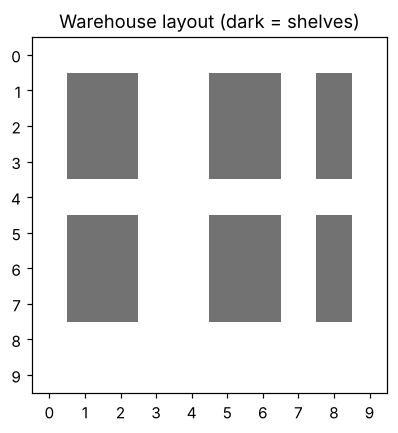

In [1]:
import sys, json; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
from src.warehouse_env import WarehouseEnv, evaluate_policy, MOVES
abl = json.load(open("../results/ablation.json"))
runs = pd.DataFrame([dict(variant=r["variant"], seed=r["seed"], **r["eval"]) for r in abl["runs"]])
env = WarehouseEnv()
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.imshow(env.grid, cmap="Greys", vmin=0, vmax=1.6); ax.set_xticks(range(env.w)); ax.set_yticks(range(env.h)); ax.grid(False)
ax.set_title("Warehouse layout (dark = shelves)"); plt.savefig("../docs/img/warehouse_layout.png", bbox_inches="tight"); plt.show()

## The table explodes

In [2]:
n = len(env.free)
states = n * (n - 1) * (n - 2) * 2        # robot, item, target positions x holding-item flag
print(f"free cells: {n}")
print(f"warehouse states: {states:,}  vs Taxi: 500")
print(f"Q-table size at 4 actions, float64: {states*4*8/1e6:.1f} MB  (and each cell needs many visits)")

free cells: 70
warehouse states: 656,880  vs Taxi: 500
Q-table size at 4 actions, float64: 21.0 MB  (and each cell needs many visits)


## A naive DQN
Network: 11 inputs (positions, holding flag, 4 blocked-neighbour flags) -> 2x128 ReLU -> 4 Q-values. Trained *online*: one gradient step per environment step, bootstrapping from the same network. 120k environment steps, 3 seeds. Code: `src/dqn.py`, experiment: `experiments/run_ablation.py`.

In [3]:
naive = runs[runs.variant == "naive"].drop(columns="variant")
print(naive.round(3).to_string(index=False))
print("\nmean over seeds:\n", naive.drop(columns="seed").mean().round(3).to_string())

 seed  delivery_rate  collision_rate  bumps_per_episode  path_efficiency
    0          0.003           0.020              1.593              1.0
    1          0.007           0.000              0.000              1.0
    2          0.000           0.133             10.663              0.0

mean over seeds:
 delivery_rate        0.003
collision_rate       0.051
bumps_per_episode    4.086
path_efficiency      0.667


## Design lesson from building the environment
In my first version a collision ended the episode with -20. In a quick 40k-step test, **all four DQN variants learned to crash straight away (0% delivery)**: early on the agent mostly crashes anyway, so continuing (-1 per step, with a crash still expected) looks worse than ending now. Changing a bump into -5 with the episode continuing fixed it. Reward design can create a policy that "prefers" failure.

## Takeaways
- Memory is *not* the problem with a table here (about 21 MB for 656,880 warehouse states). **Coverage** is: the whole 120k-step training budget is smaller than the number of states, so a table cannot even visit each state once, and it cannot generalise between similar situations. A neural network can.
- A naive DQN (online updates, bootstrapping from itself) fails: **0.3% mean delivery across 3 seeds**, with unstable collision behaviour (one seed bumped ~10.7 times per episode).
- Reward design matters: with episode-ending collisions, every variant learned to crash immediately in my first test.